# Data exploration

Thin runner over `iiss.data.eda`, `iiss.data.validate` and `iiss.analysis.viz`. All logic lives in `src/iiss/`; this notebook only sets parameters, calls functions and shows the results.

- Tables and figures are written to `results/eda/` (same files as `python -m iiss.data.eda`).
- Images are loaded with `iiss.data.images.load_image`, so the 4 rotation-fixed images line up with their masks.
- Runs on CPU in about a minute. `SMOKE = True` only reduces the number of sample images.

## Parameters

In [3]:
SPLITS = ['train', 'valid', 'test']
N_SAMPLES = 6          # sample images per split in the gallery
SEED = 42
SAVE_GALLERIES = True  # also write results/eda/samples_<split>.jpg
SMOKE = False          # True: 3 samples per split, no saved galleries

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from iiss.analysis.viz import sample_gallery
from iiss.data.coco import load_split
from iiss.data.eda import run_eda
from iiss.data.images import default_rotation_fixes
from iiss.utils.config import load_yaml
from iiss.utils.log import setup_logging
from iiss.utils.paths import repo_root

setup_logging()
if SMOKE:
    N_SAMPLES, SAVE_GALLERIES = 3, False
ROOT = repo_root()
BASE = load_yaml(ROOT / 'configs' / 'base.yaml')
EDA_DIR = ROOT / BASE['paths']['results_root'] / 'eda'
FIXES = default_rotation_fixes()
pd.set_option('display.max_columns', 20)

## Dataset validation status

From `results/data_validation.md` (regenerate with `python -m iiss.data.validate`).

In [5]:
report = (ROOT / BASE['paths']['results_root'] / 'data_validation.md').read_text(encoding='utf-8')
display(Markdown('\n'.join(l for l in report.splitlines() if l.startswith('- '))))

- Generated: 2026-11-18T00:35:07+07:00
- Dataset root: `dataset/panoptic-indoor-segmentation.v5i.coco-segmentation`
- Command: `python -m iiss.data.validate`
- Result: **PASS** (0 error checks, 5 warning checks)
- **train**: 640x480 (359), 640x640 (19), 720x480 (5), 853x640 (2), 640x501 (1)
- **valid**: 640x480 (152), 640x640 (7), 640x510 (1), 641x480 (1), 719x480 (1)
- **test**: 960x1280 (31), 750x500 (24), 225x225 (13), 275x183 (12), 720x1280 (8)
- **train** (10): `indoor-objects`, `flower`, `hair drier`, `keyboard`, `mouse`, `scissor`, `scissors`, `teddy bear`, `toaster`, `toothbrush`
- **valid** (17): `indoor-objects`, `cardboard`, `clock`, `curtain`, `flower`, `hair drier`, `keyboard`, `mouse`, `scissor`, `scissors`, `st-`, `teddy bear`, `toothbrush`, `tree-merged`, `vase`, `wall`, `wall-stone`
- **test** (6): `indoor-objects`, `remote`, `shelf`, `st-`, `tree-merged`, `wall`

## Run the EDA

In [6]:
files = run_eda(BASE['paths']['dataset_root'], SPLITS, EDA_DIR)
sorted(p.name for p in files.values())

2026-11-18 13:28:42 INFO    iiss.data.eda: Wrote 11 EDA files to C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\results\eda


['class_counts.csv',
 'class_counts.png',
 'class_shift.csv',
 'image_sizes.csv',
 'instances_per_image.csv',
 'instances_per_image_hist.png',
 'long_side_hist.png',
 'long_side_stats.csv',
 'object_sizes.csv',
 'small_objects_vs_S.png',
 'summary.md']

## Image sizes and resize direction per input size S

,split,images,min,p25,median,p75,max,upscaled_pct_at_320,downscaled_pct_at_320,upscaled_pct_at_640,downscaled_pct_at_640,upscaled_pct_at_960,downscaled_pct_at_960
0,train,397,561,640.0,640.0,640.0,857,0.00,100.00,0.25,4.03,100.00,0.00
1,valid,166,640,640.0,640.0,640.0,857,0.00,100.00,0.00,3.61,100.00,0.00
2,test,359,225,600.0,800.0,1280.0,3398,14.76,85.24,28.13,67.97,58.22,40.39


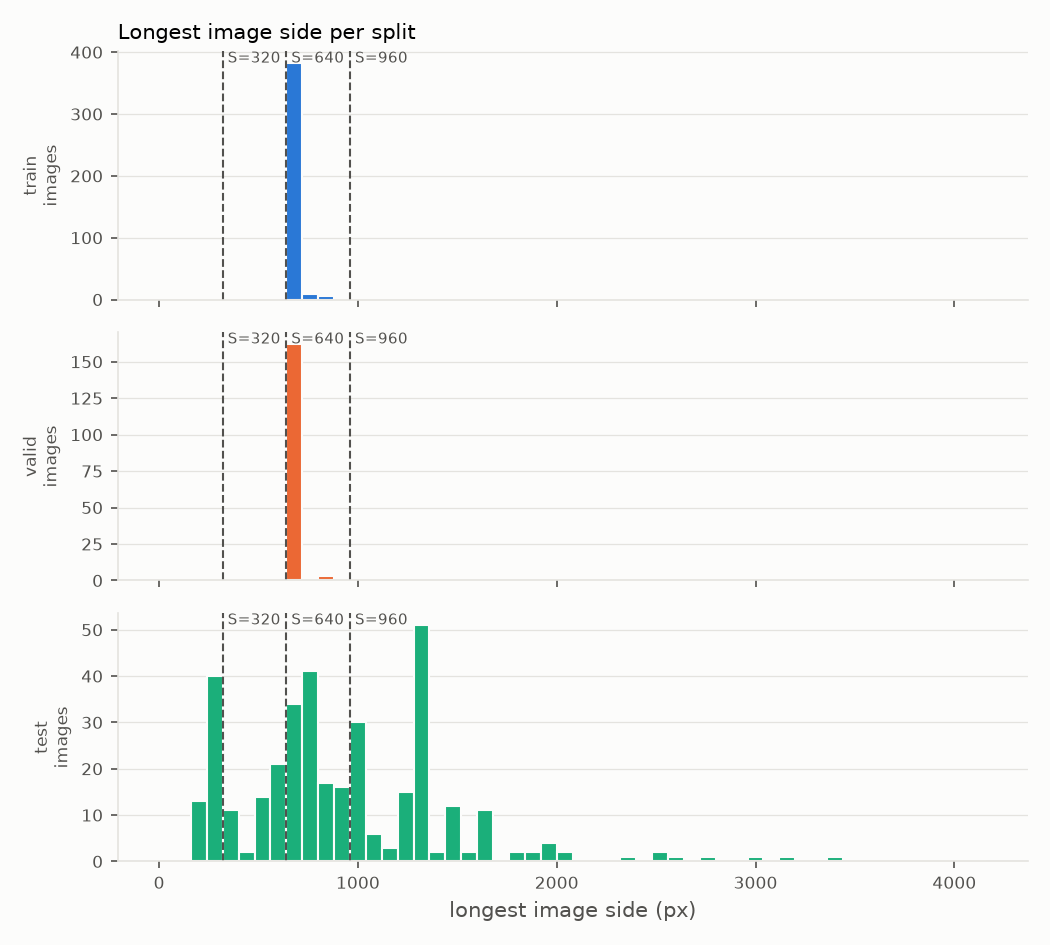

In [7]:
display(pd.read_csv(files['long_side_stats']))
display(Image(filename=files['long_side_png'], width=650))

## Instances per image

,split,images,mean,median,p90,max,zero
0,train,397,11.28,8.0,22.0,61,0
1,valid,166,12.18,9.0,21.5,79,1
2,test,359,14.89,12.0,26.0,129,0


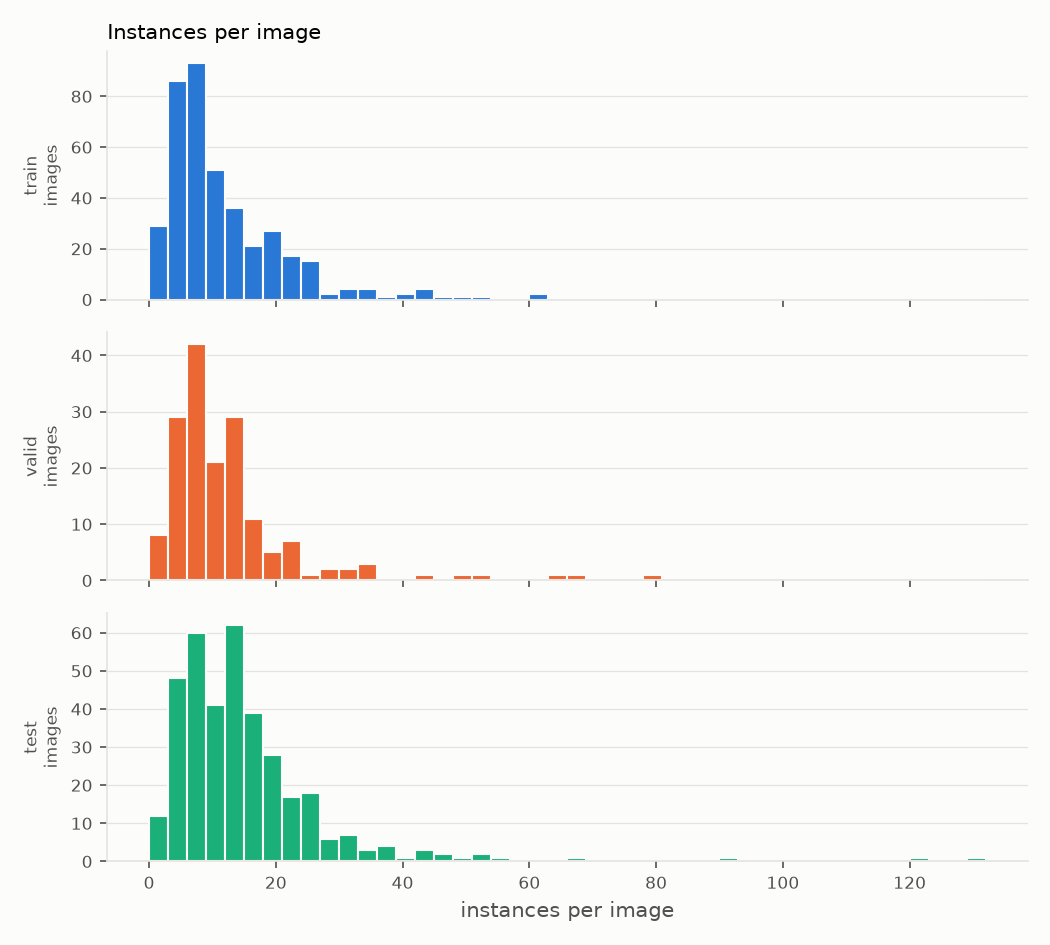

In [8]:
display(pd.read_csv(files['instances_per_image']))
display(Image(filename=files['ipi_png'], width=650))

## Object sizes at native resolution and after resizing to S

COCO bins: small < 32², medium < 96², large ≥ 96² px².

,split,resolution,instances,small_pct,medium_pct,large_pct,median_sqrt_area_px
0,train,native,4479,11.03,31.41,57.56,119.0
1,train,S=320,4479,28.64,39.18,32.17,59.0
2,train,S=640,4479,11.07,31.44,57.49,118.0
3,train,S=960,4479,4.89,23.76,71.36,177.0
4,valid,native,2022,9.64,33.58,56.78,115.1
5,valid,S=320,2022,28.09,41.35,30.56,57.4
6,valid,S=640,2022,9.79,33.53,56.68,114.8
7,valid,S=960,2022,3.76,24.33,71.91,172.1
8,test,native,5344,10.74,31.92,57.34,117.7
9,test,S=320,5344,36.88,42.53,20.58,45.3


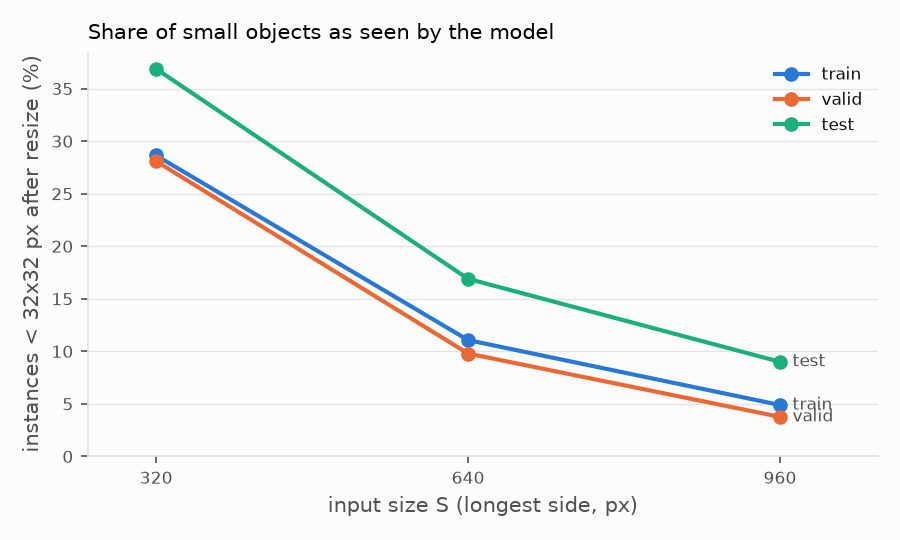

In [9]:
display(pd.read_csv(files['object_sizes']))
display(Image(filename=files['small_png'], width=550))

## Class counts per split

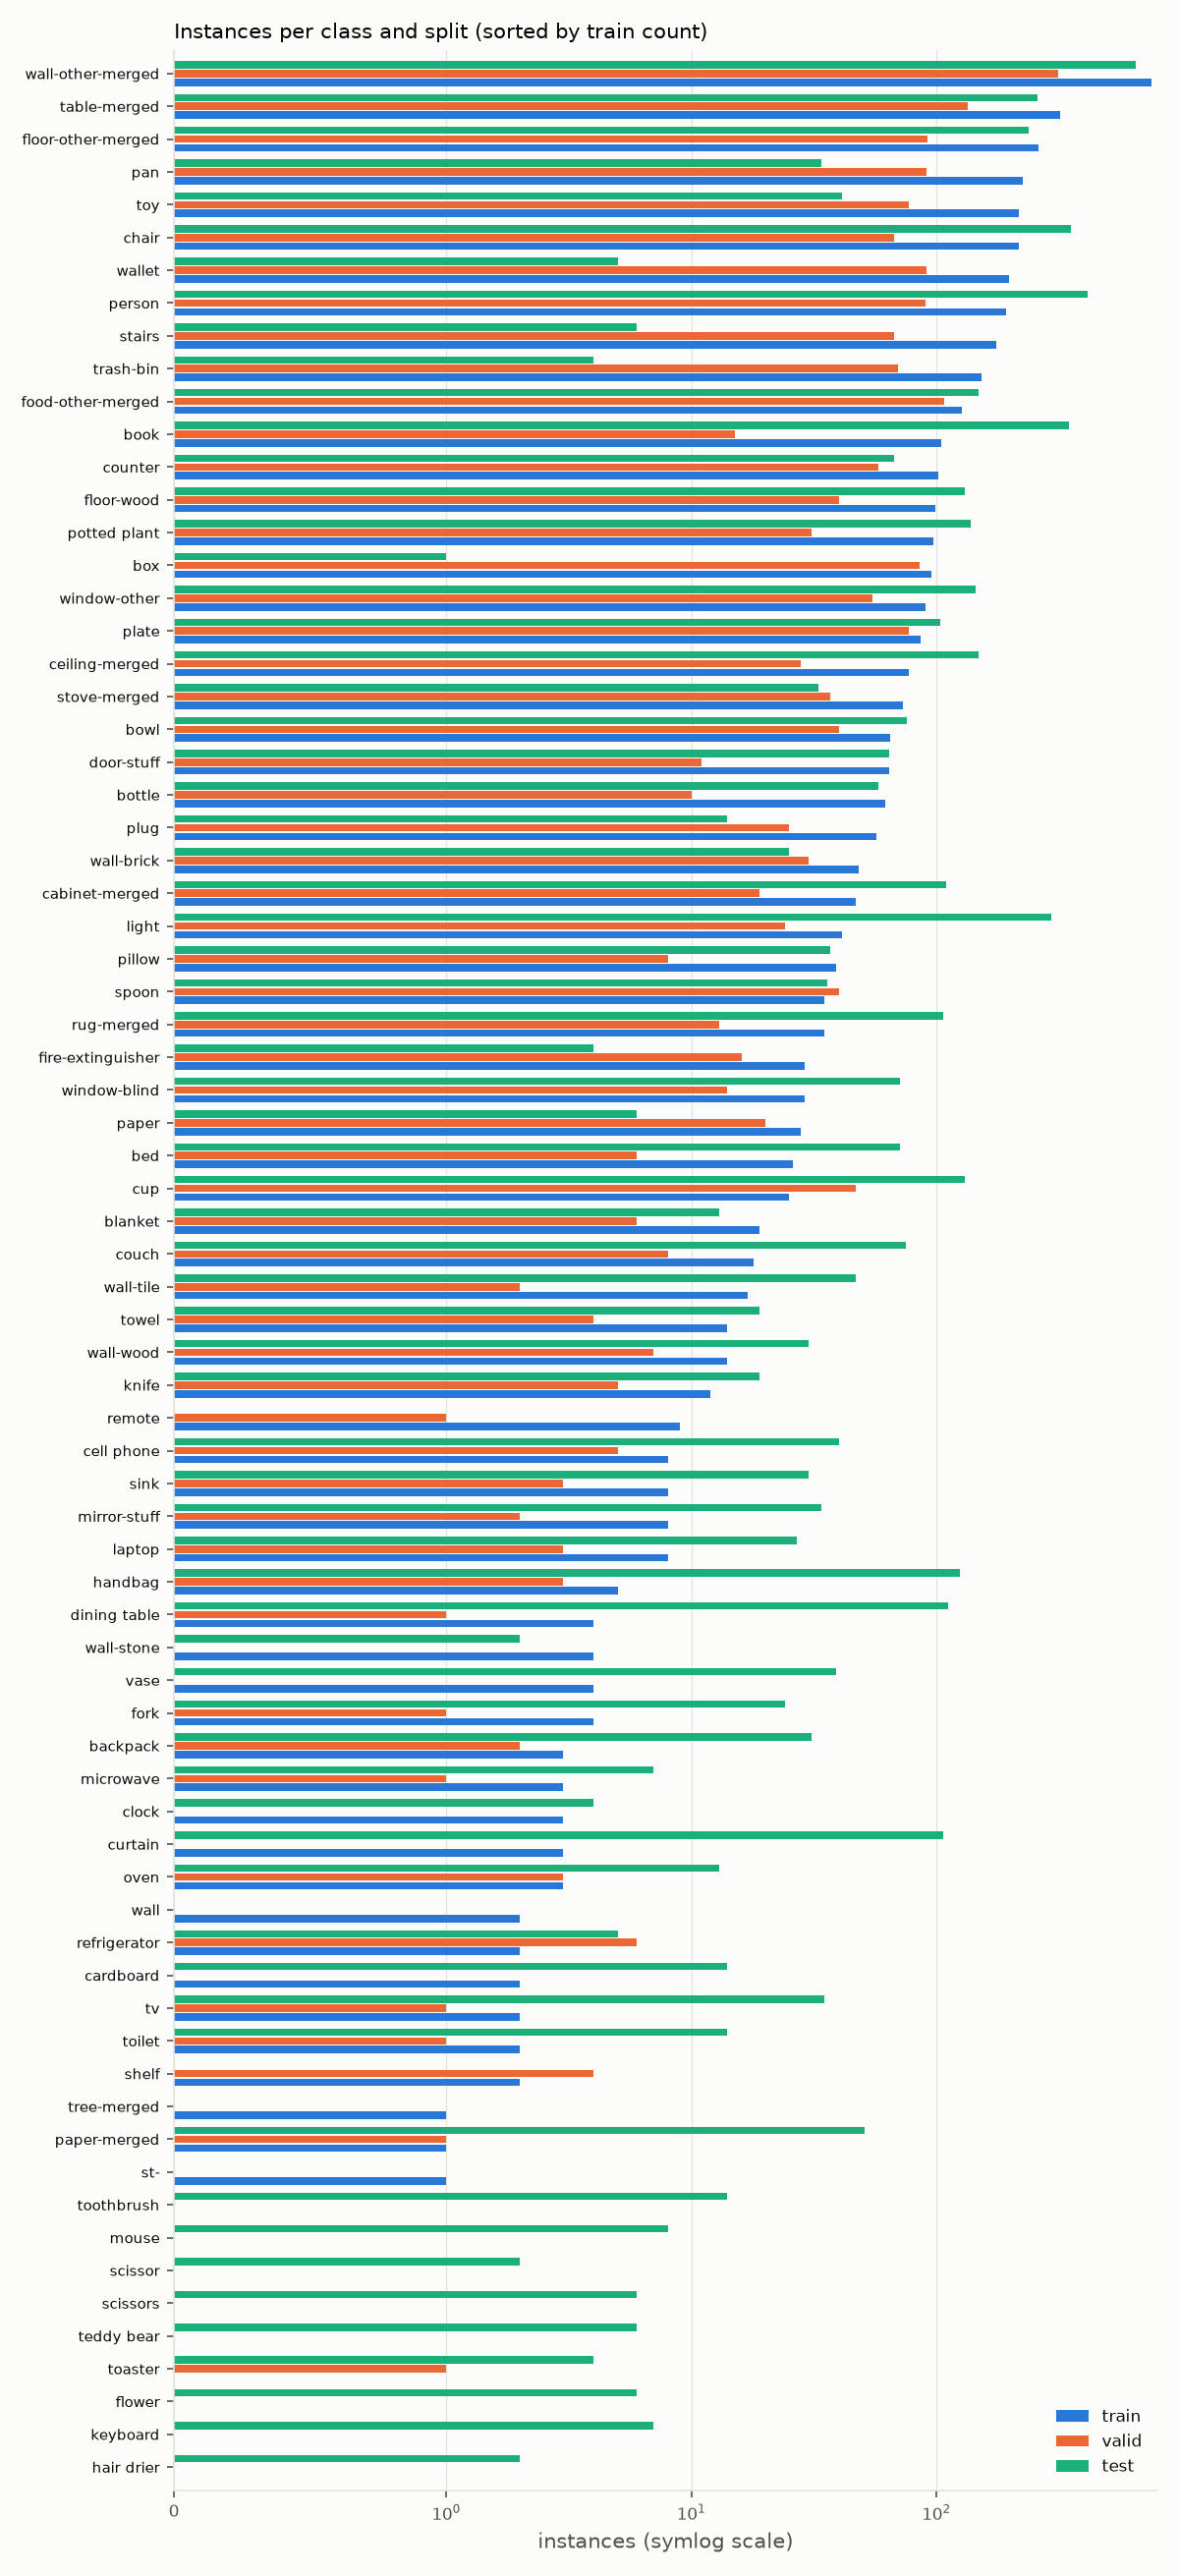

In [10]:
display(Image(filename=files['class_counts_png'], width=700))

## Train vs test class shift

Sorted by absolute change in instance share (percentage points).

In [11]:
shift = pd.read_csv(files['class_shift'])
display(shift[shift['status'] != 'present_in_both'])
display(shift[shift['status'] == 'present_in_both'].head(15))

,id,name,train_instances,test_instances,train_share_pct,test_share_pct,share_diff_pp,share_ratio,status
42,59,toothbrush,0,14,0.000,0.262,0.262,NaN,absent_in_train
48,45,remote,9,0,0.201,0.000,-0.201,0.0,absent_in_test
52,34,mouse,0,8,0.000,0.150,0.150,NaN,absent_in_train
53,28,keyboard,0,7,0.000,0.131,0.131,NaN,absent_in_train
54,23,flower,0,6,0.000,0.112,0.112,NaN,absent_in_train
55,48,scissors,0,6,0.000,0.112,0.112,NaN,absent_in_train
56,56,teddy bear,0,6,0.000,0.112,0.112,NaN,absent_in_train
59,57,toaster,0,4,0.000,0.075,0.075,NaN,absent_in_train
64,66,wall,2,0,0.045,0.000,-0.045,0.0,absent_in_test
65,49,shelf,2,0,0.045,0.000,-0.045,0.0,absent_in_test


,id,name,train_instances,test_instances,train_share_pct,test_share_pct,share_diff_pp,share_ratio,status
0,68,wall-other-merged,756,650,16.879,12.163,-4.716,0.721,present_in_both
1,31,light,41,295,0.915,5.520,4.605,6.033,present_in_both
2,36,pan,225,34,5.023,0.636,-4.387,0.127,present_in_both
3,72,wallet,197,5,4.398,0.094,-4.304,0.021,present_in_both
4,4,book,105,349,2.344,6.531,4.187,2.786,present_in_both
5,61,toy,217,41,4.845,0.767,-4.078,0.158,present_in_both
6,53,stairs,175,6,3.907,0.112,-3.795,0.029,present_in_both
7,39,person,192,413,4.287,7.728,3.441,1.803,present_in_both
8,62,trash-bin,153,4,3.416,0.075,-3.341,0.022,present_in_both
9,55,table-merged,319,258,7.122,4.828,-2.294,0.678,present_in_both


## Sample images with ground-truth masks

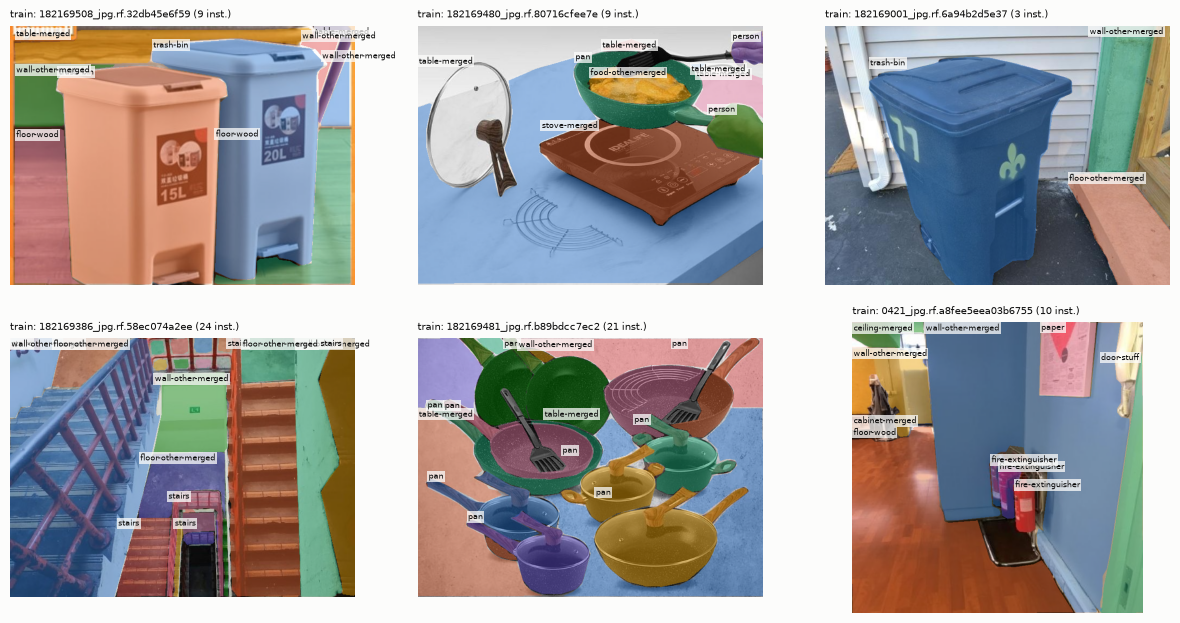

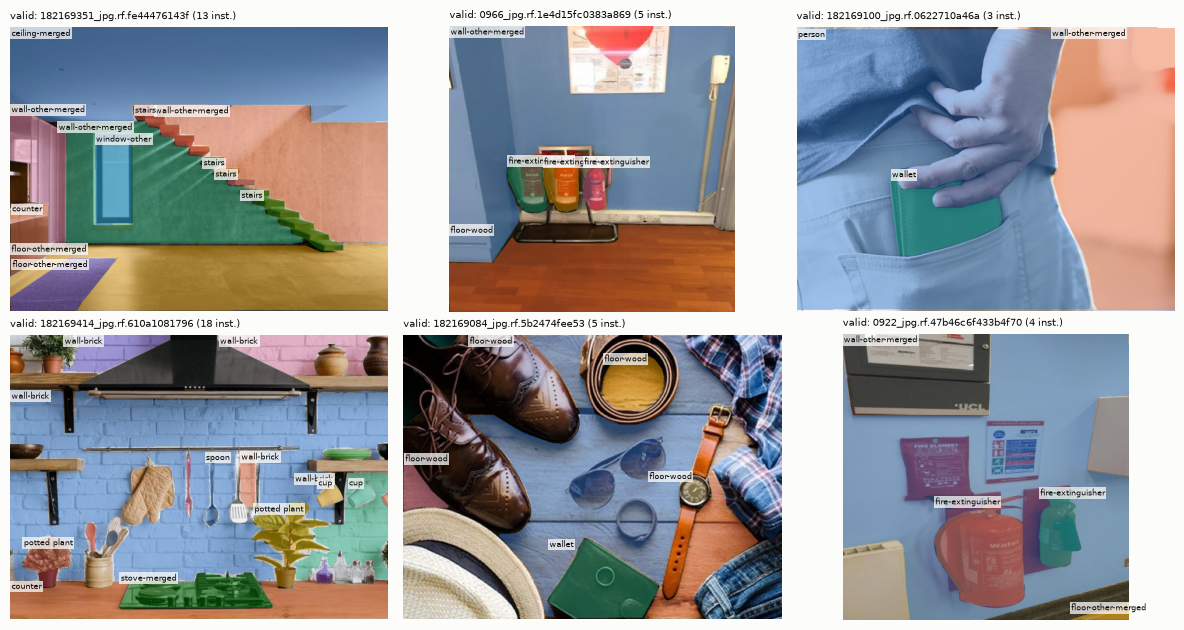

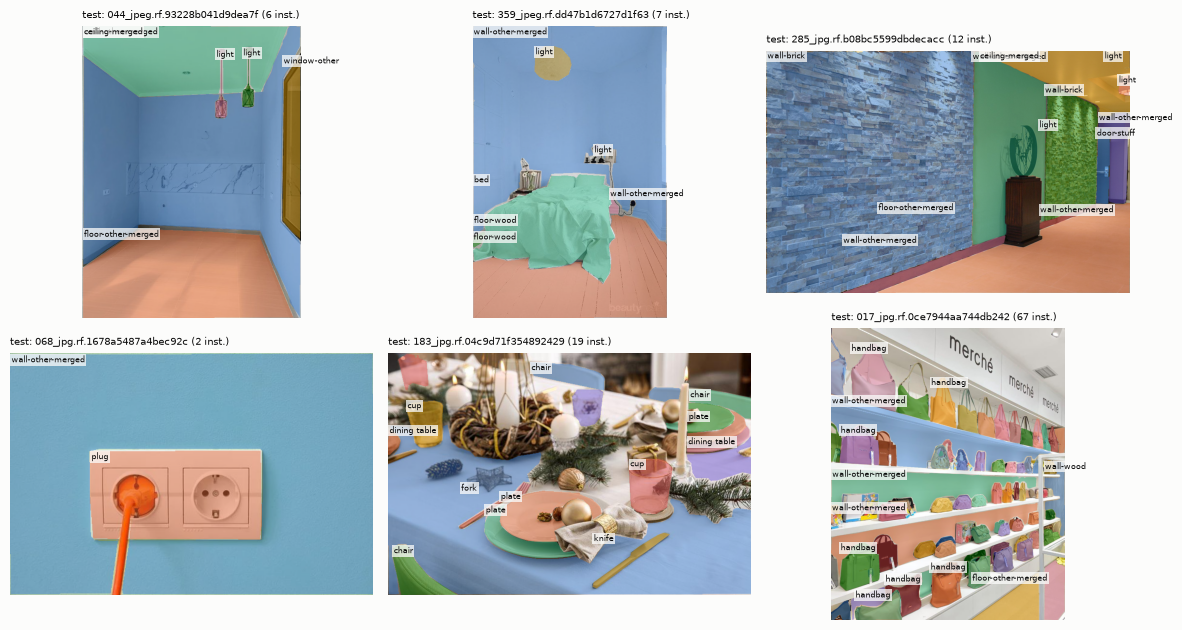

In [12]:
for name in SPLITS:
    split = load_split(BASE['paths']['dataset_root'], name)
    fig = sample_gallery(split, n=N_SAMPLES, seed=SEED, fixes=FIXES)
    if SAVE_GALLERIES:
        fig.savefig(EDA_DIR / f'samples_{name}.jpg', dpi=80, pil_kwargs={'quality': 85})
    display(fig)
    plt.close(fig)

## Rotation-fixed images

These 4 files are stored rotated by 90° relative to their annotations; `load_image` rotates them back (`data.rotation_fixes`).

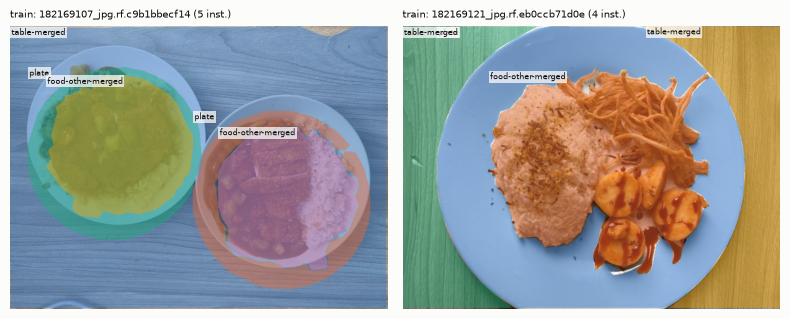

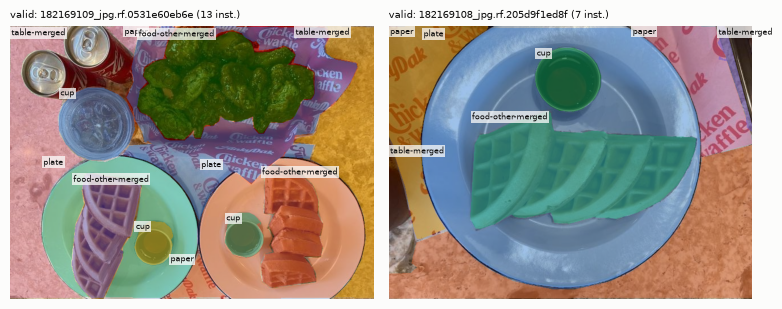

In [13]:
for name in ['train', 'valid']:
    split = load_split(BASE['paths']['dataset_root'], name)
    fixed = [i['file_name'] for i in split.images if i['file_name'] in FIXES]
    fig = sample_gallery(split, file_names=fixed, fixes=FIXES, cols=2)
    display(fig)
    plt.close(fig)